In [57]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 
import ast

In [3]:
character_anime_works = pd.read_csv(r'../data/character_anime_works.csv')
character_anime_works.tail()

,anime_mal_id,character_mal_id,character_name,role
236811,31245,137157,"Shibasaki, Ken",Supporting
236812,36305,136064,"Hamanaka, Midori",Main
236813,36305,133916,"Narumi, Sena",Main
236814,36305,124942,"Hayasaka, Akari",Supporting
236815,34895,155887,"Shiraha, Setsuna",Main


In [4]:
character_anime_works.shape

(236816, 4)

In [5]:
character_anime_works.columns

Index(['anime_mal_id', 'character_mal_id', 'character_name', 'role'], dtype='object')

In [6]:
character_anime_works.dtypes

anime_mal_id         int64
character_mal_id     int64
character_name      object
role                object
dtype: object

In [7]:
character_anime_works['role'].value_counts()

role
Supporting    186285
Main           50531
Name: count, dtype: int64

### Characters' details

In [5]:
characters = pd.read_csv(r'../data/characters.csv')
characters

NameError: name 'pd' is not defined

In [ ]:
characters.shape

(209963, 7)

In [ ]:
characters.columns

Index(['character_mal_id', 'url', 'name', 'name_kanji', 'image', 'favorites',
       'about'],
      dtype='object')

In [ ]:
characters.dtypes

character_mal_id    float64
url                  object
name                 object
name_kanji           object
image                object
favorites           float64
about                object
dtype: object

Duplicated ID - repeated informations error.

Based on our notes during the course, in this case we should remove them keeping only the first occurrence to avoid changing mean and other statistics

In [ ]:
# Counts duplicated ID
duplicate_count = characters['character_mal_id'].duplicated().sum()
print(f"ID duplicati trovati: {duplicate_count}")

# To see duplicated rows
if duplicate_count > 0:
    print(characters[characters['character_mal_id'].duplicated(keep=False)].sort_values(by='character_mal_id'))

ID duplicati trovati: 456
        character_mal_id                                                url  \
208187             546.0       https://myanimelist.net/character/546/Hayate   
208185             546.0       https://myanimelist.net/character/546/Hayate   
208186             546.0       https://myanimelist.net/character/546/Hayate   
204358            4527.0  https://myanimelist.net/character/4527/Narue_N...   
204356            4527.0  https://myanimelist.net/character/4527/Narue_N...   
...                  ...                                                ...   
209850          282115.0    https://myanimelist.net/character/282115/Cavitt   
209859          282131.0  https://myanimelist.net/character/282131/Lieut...   
209858          282131.0  https://myanimelist.net/character/282131/Lieut...   
209733               NaN                                                NaN   
209734               NaN                                                NaN   

                     name

In [ ]:
# Removing duplicates and keeping first record found
#characters = characters.loc[~characters.duplicated(subset=['character_mal_id'])]

# Confirm current status
#print(f"Dataset dopo la rimozione duplicati: {len(characters)} righe")

Column 'favorites' - meaning: describing how many times a user add the character to his/her/its favourites

In [ ]:
characters['favorites'].describe()

count    209961.000000
mean         57.616138
std        1197.586488
min           0.000000
25%           0.000000
50%           0.000000
75%           2.000000
max      175632.000000
Name: favorites, dtype: float64

1. **High percentage of zero values**: usual event of large-scale dataset: a  few characters (the famous protagonists) have thousands of likes, while the vast majority of secondary characters have zero or very few of them.
2. **Type anomaly**: The dtype is float64, but the "likes" are necessary integers.

Solutions
- **Memory optimization**: convert column values into int32. Float64 value type takes up a lot of space.

- **Outlier management**: the maximum value of 175.632 is an important signal (the most loved character), not an error. Don't remove but use it to generate a categorization (es. "Top Tier", "Mainstream", "Niche") to encourage analysis for expert users.

- **Cardinality Filter**: If you're only interested in relevant people for your "Data Story", you could create a view of the data frame that excludes those with zero favorites, reducing the cardinality; this allows you to "work with seemingly smaller data" and focus only on the portion of data actually needed for popularity analysis.

In [ ]:
# Memory optimization - replacing NaN values with 0 (not in favorites) and convert
characters['favorites'] = characters['favorites'].fillna(0).astype('int32')
print(characters['favorites'].dtypes)

int32


In [ ]:
# Outlier management

In [ ]:
# Cardinality Filter - generating a view which avoid rows with 'favorites' values = 0
characters_fav_view = characters[characters['favorites'] > 0]

# If we don't need original data, reallocate to save memory
# characters = characters[characters['favorites'] > 0]

print(f"View rows (character with fav > 0): {len(characters_fav_view)}")

This convert the highest value to essential knowledge to the audience.

Column 'about' meaning - character's biography

In [ ]:
characters['about'].value_counts()

about
No voice actors have been added to this character. Help improve our database by searching for a voice actor, and adding this character to their roles .                                                                                                                                                                                                                                                                                                                                                                                                              199
Appears in episode 1.                                                                                                                                                                                                                                                                                                                                                                                                                                    

**Data Interpretation**: the 199 occurrences of "No voice actors have been added..." and short descriptions like "Appears in episode 1" are signs of poor or missing data, even though they are not formally NaNs.

Thoughts
1. **Replacement**: Is it better to replace Nan with "No info"?
2. **Length Analysis**: Instead of reading the text, create a new column about_length. There's often a correlation between a character's popularity and the length of their description.
3. **Radical Memory Savings**: If you don't plan on doing text analysis, this column takes up a lot of RAM. Out notes suggest that if it's not needed for the current analysis, it's best to drop it or not load it at all to save space.

In [ ]:
# Replacement - improves readability
characters['about'] = characters['about'].fillna('No info')

If a journalist reads a profile, he/she'll be albe to understand the information more clearly than an empty space or a technical error.

In [ ]:
# Total for each column
print(characters.isna().sum())

# Total of each row which contains at least a NaN value
print(f"Totale righe con almeno un NaN: {characters.isna().any(axis=1).sum()}")

character_mal_id        2
url                     2
name                    2
name_kanji          55480
image                   2
favorites               0
about                   0
dtype: int64
Totale righe con almeno un NaN: 55480


The data extracted shows that 125,436 of 209,963 rows (about 60% of the dataset) have at least one null value.

What does this mean?

- **Massive Loss**: If you used a simple dropna(), you would delete more than half of your database.

- **Nature of the data**: Most of the NaNs are found in _about_ (96,976) and _name_kanji_ (55,480). It's common for many characters to lack a biography or Japanese name in the database.

To do:
- **Avoid Bias**: If you remove a row due to a NaN in an irrelevant column (such as name_kanji if you're doing a statistical analysis of favorites), your analysis will be highly biased, i.e., incorrect.

- **Leverage Pandas' design**: Pandas is designed to skip NaNs during numeric operations, so their presence will not affect the calculation of the favorites average.

- **Critical columns**: Only remove rows if the NaN is present in character_mal_id or name, since without this data the element becomes meaningless.

In [ ]:
# We only remove if essential identity data is missing
#characters = characters.dropna(subset=['character_mal_id', 'name'])

# For the others, we do not delete anything to avoid bias
#print(f"Percentuale di dati preservati: {len(characters)/209963*100:.2f}%")

In [102]:
details_df = pd.read_csv(r'../data/Details.csv')
details_df.tail()

,mal_id,title,title_japanese,url,image_url,type,status,score,scored_by,start_date,...,demographics,source,rating,episodes,season,year,producers,explicit_genres,licensors,streaming
28950,59421,Zutaboro Reijou wa Ane no Moto Konyakusha ni D...,ずたぼろ令嬢は姉の元婚約者に溺愛される,https://myanimelist.net/anime/59421/Zutaboro_R...,https://cdn.myanimelist.net/images/anime/1518/...,TV,Finished Airing,7.37,15624.0,2025-07-05T00:00:00+00:00,...,['Josei'],Light novel,PG-13 - Teens 13 or older,12.0,summer,2025.0,"['Studio Pierrot', 'Mainichi Broadcasting Syst...",[],[],"['Crunchyroll', 'Aniplus TV', 'Bahamut Anime C..."
28951,31245,Zutto Mae kara Suki deshita. Kokuhaku Jikkou I...,ずっと前から好きでした。～告白実行委員会～,https://myanimelist.net/anime/31245/Zutto_Mae_...,https://cdn.myanimelist.net/images/anime/3/821...,Movie,Finished Airing,7.20,104106.0,2016-04-23T00:00:00+00:00,...,[],Music,PG-13 - Teens 13 or older,1.0,NaN,NaN,"['Aniplex', 'Dentsu', 'Kadokawa Shoten', 'Movi...",[],['Aniplex of America'],[]
28952,36305,Zutto Mae kara Suki deshita. Kokuhaku Jikkou I...,ずっと前から好きでした。～告白実行委員会～ 「金曜日のおはよう」,https://myanimelist.net/anime/36305/Zutto_Mae_...,https://cdn.myanimelist.net/images/anime/6/883...,Special,Finished Airing,7.17,10038.0,2016-10-26T00:00:00+00:00,...,[],Music,PG - Children,1.0,NaN,NaN,['Aniplex'],[],[],[]
28953,34895,Zutto Suki Datta,ずっと好きだった,https://myanimelist.net/anime/34895/Zutto_Suki...,https://cdn.myanimelist.net/images/anime/1498/...,OVA,Finished Airing,5.68,1887.0,2017-04-21T00:00:00+00:00,...,[],Manga,Rx - Hentai,2.0,NaN,NaN,"['Queen Bee', 'Mediabank']",[],[],[]
28954,56606,Zutto Tomodachi,ずっと友達,https://myanimelist.net/anime/56606/Zutto_Tomo...,https://cdn.myanimelist.net/images/anime/1462/...,Music,Finished Airing,NaN,NaN,1996-06-01T00:00:00+00:00,...,['Kids'],Original,G - All Ages,1.0,NaN,NaN,['NHK'],[],[],[]


In [103]:
details_df.shape

(28955, 29)

In [104]:
details_df.columns

Index(['mal_id', 'title', 'title_japanese', 'url', 'image_url', 'type',
       'status', 'score', 'scored_by', 'start_date', 'end_date', 'synopsis',
       'rank', 'popularity', 'members', 'favorites', 'genres', 'studios',
       'themes', 'demographics', 'source', 'rating', 'episodes', 'season',
       'year', 'producers', 'explicit_genres', 'licensors', 'streaming'],
      dtype='object')

In [105]:
details_df.dtypes

mal_id               int64
title               object
title_japanese      object
url                 object
image_url           object
type                object
status              object
score              float64
scored_by          float64
start_date          object
end_date            object
synopsis            object
rank               float64
popularity           int64
members              int64
favorites            int64
genres              object
studios             object
themes              object
demographics        object
source              object
rating              object
episodes           float64
season              object
year               float64
producers           object
explicit_genres     object
licensors           object
streaming           object
dtype: object

### CONVERSIONE DATE E ANNO DI RILASCIO
Conversione della colonna start_date in formato datetime e estrazione dell' anno per facilitare i successivi passaggi per la colonna release_year

In [115]:
details_df['start_date'] = pd.to_datetime(details_df['start_date'], errors='coerce')
details_df['release_year'] = details_df['start_date'].dt.year
# Estrae i primi 10 valori di entrambe le colonne per vedere il formato testuale
print(details_df[['start_date', 'end_date']].head(10))

# Mostra anche i valori unici per capire se ci sono formati "sporchi" o diversi
print("\nValori unici nella colonna start_date:")
print(details_df['start_date'].unique()[:10])

                 start_date                   end_date
0 2010-01-01 00:00:00+00:00                        NaN
1 2023-06-11 00:00:00+00:00                        NaN
2 2007-01-18 00:00:00+00:00                        NaN
3 2007-12-22 00:00:00+00:00                        NaN
4 2008-03-25 00:00:00+00:00                        NaN
5 2003-11-16 00:00:00+00:00                        NaN
6 2003-03-28 00:00:00+00:00                        NaN
7 2002-06-20 00:00:00+00:00  2003-04-10T00:00:00+00:00
8 2011-01-28 00:00:00+00:00  2011-04-07T00:00:00+00:00
9 2011-01-28 00:00:00+00:00  2011-04-07T00:00:00+00:00

Valori unici nella colonna start_date:
<DatetimeArray>
['2010-01-01 00:00:00+00:00', '2023-06-11 00:00:00+00:00',
 '2007-01-18 00:00:00+00:00', '2007-12-22 00:00:00+00:00',
 '2008-03-25 00:00:00+00:00', '2003-11-16 00:00:00+00:00',
 '2003-03-28 00:00:00+00:00', '2002-06-20 00:00:00+00:00',
 '2011-01-28 00:00:00+00:00', '2006-04-06 00:00:00+00:00']
Length: 10, dtype: datetime64[ns, UTC]


Trasformazione dati anomali in  NaT (Not a Time) utilizziando errors='coerence' per garantire un' accuratezza maggiore per le analisi

In [108]:
# Controllo valori mancanti per TUTTE le colonne
missing_values = details_df.isna().sum()
print("Valori mancanti per colonna:")
print(missing_values[missing_values > 0]) 

Valori mancanti per colonna:
title_japanese      119
type                 67
score             10073
scored_by         10073
start_date          851
end_date          17688
synopsis           5127
rank               6958
rating              600
episodes            680
season            22689
year              22689
release_year        851
dtype: int64


### DISTRIBUZIONE VOTI  
Distribuzione basata sullo score dei vari anime

In [109]:
# Statistiche generali sui voti
print("Distribuzione dello Score:")
display(details_df['score'].describe()) 
# Controlliamo se ci sono voti potenzialmente anomali 
outliers_score = details_df.query('score > 10 or score <= 0')
print(f"Numero di outlier rilevati nello score: {len(outliers_score)}")

if len(outliers_score) > 0:
    display(outliers_score)

Distribuzione dello Score:


count    18882.000000
mean         6.390500
std          0.892045
min          1.890000
25%          5.770000
50%          6.360000
75%          7.030000
max          9.290000
Name: score, dtype: float64

Numero di outlier rilevati nello score: 0


### ANALISI DELLA DISTRIBUZIONE E DELLA CRESCITA DEI GENERI
In questa fase, l'obiettivo è esplorare la composizione tematica del dataset. Nella colonna genres i dati sono stati importati come tipo object (stringhe), contenenti rappresentazioni testuali di liste. Per procedere con un'analisi granulare, è necessario un processo di Data Cleaning e Normalizzazione.

Utilizziamo il modulo ast per convertire le stringhe in oggetti lista Python. Questo passaggio è fondamentale per rendere i dati "comprensibili" agli algoritmi di analisi.

**Normalizzazione**: Poiché un singolo anime può appartenere a più categorie (es. "Action, Adventure"), abbiamo "esploso" le liste in entità singole. Questa operazione evita il bias di considerare combinazioni di generi come etichette uniche, permettendo un conteggio accurato di ogni singola occorrenza.

**Analisi Globale**: Un primo grafico a barre illustrerà la distribuzione completa di tutti i generi per identificare i pilastri del mercato.

**Focus Evolutivo**: Analizzeremo l'andamento temporale dei Top 5 generi per volumi di produzione. Per massimizzare la leggibilità, utilizzeremo intervalli quinquennali (ogni 5 anni), evidenziando i trend di crescita storici dal 1960 al 2023.

In [114]:
# Comprensione il formato
print("\nFormato colonna genres:")
details_df['genres'].head()


Formato colonna genres:


0                           ['Comedy']
1           ['Horror', 'Supernatural']
2    ['Adventure', 'Drama', 'Fantasy']
3                ['Action', 'Fantasy']
4      ['Comedy', 'Fantasy', 'Sci-Fi']
Name: genres, dtype: object


Generi più frequenti:
genres
Comedy           7779
Fantasy          6035
Action           5665
Adventure        4428
Sci-Fi           3472
Drama            3095
Romance          2195
Slice of Life    1596
Hentai           1591
Supernatural     1572
Avant Garde      1061
Mystery           999
Ecchi             820
Sports            819
Horror            581
Suspense          455
Award Winning     257
Gourmet           233
Boys Love         196
Girls Love        121
Erotica            82
Name: count, dtype: int64


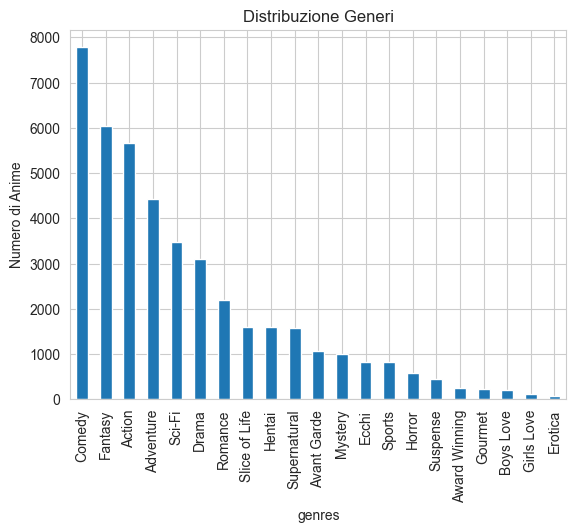

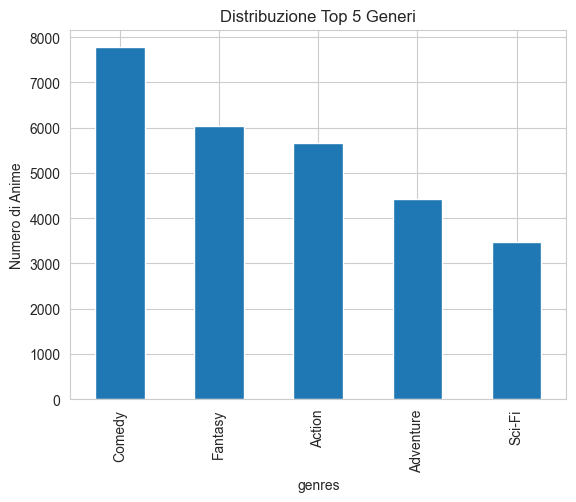

In [ ]:
# Conversione da stringa a lista
genres_cleaned_series = details_df['genres'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) and x.startswith('[') else x if isinstance(x, list) else [] )

genres_series = genres_cleaned_series.explode()
genre_counts = genres_series.value_counts()

print("\nGeneri più frequenti:")
print(genre_counts)

# Visualizzazione
genre_counts.plot(kind='bar', title='Distribuzione Generi')
plt.ylabel('Numero di Anime')
plt.show()

genre_counts.head(5).plot(kind='bar', title='Distribuzione Top 5 Generi')
plt.ylabel('Numero di Anime')
plt.show()


### Analisi della Crescita Storica dei Generi (1960 - 2023)
In questa sezione, l'obiettivo è analizzare come la produzione dei 5 generi più popolari si è evoluta nel tempo . Per garantire un'analisi accurata e professionale, abbiamo adottato una strategia di Data Transformation che preserva l'integrità del dataset originale.

- **Preprocessing Temporaneo**: Abbiamo convertito la colonna start_date in oggetti datetime all'interno di variabili locali. L'uso dell'accessore .dt per l'estrazione dell'anno è avvenuto senza modificare permanentemente il DataFrame originale, evitando ridondanze in memoria .

- **Modularità dei Dati**: È stato creato un DataFrame di supporto dedicato esclusivamente a questa visualizzazione . Questo ha permesso di isolare la logica di esplosione dei generi (necessaria essendo la colonna di tipo object) dalla struttura dati principale .

- **Visualizzazione Narrativa**: La suddivisione dell'asse temporale è stata impostata con intervalli di 5 anni. Questa scelta permette di evidenziare i cicli di crescita in modo chiaro e scansionato, rendendo il grafico un "headline" immediato per il lettore.

- **Accuratezza Statistica**: L'analisi copre il periodo dal 1960 al 2023. Abbiamo escluso i dati dal 2024 in poi poiché, trattandosi di un'annualità incompleta, avrebbe mostrato un calo di produzione fittizio non rappresentativo dei reali trend di mercato .

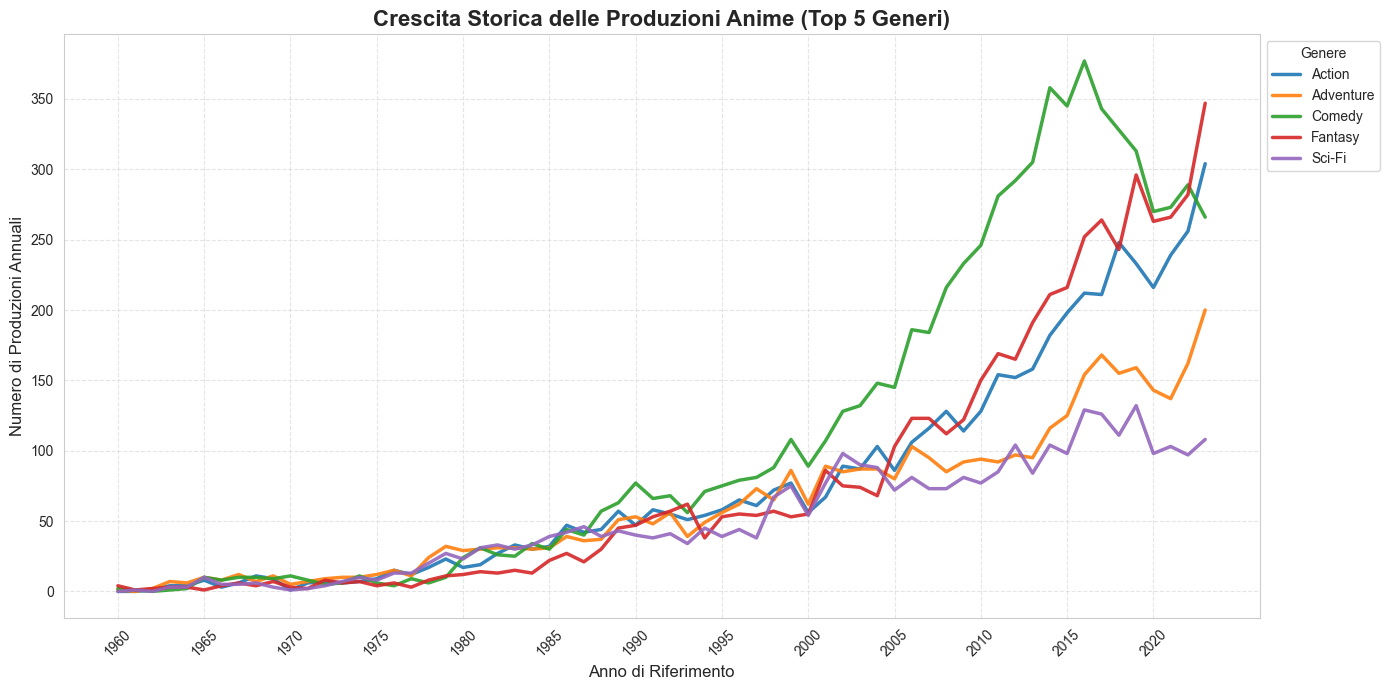

In [112]:
temp_genres = details_df['genres'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) 
                                         and x.startswith('[') else x if isinstance(x, list) else [])

temp_datetime = pd.to_datetime(details_df['start_date'], errors='coerce') 
temp_years = temp_datetime.dt.year
# Creazione DataFrame di analisi 
df_growth = pd.DataFrame({'year': temp_years,'genre': temp_genres}).explode('genre')

top_5_labels = df_growth['genre'].value_counts().head(5).index.tolist()
df_top_5 = df_growth[df_growth['genre'].isin(top_5_labels)]

# Raggruppamento annuale 
growth_data = df_top_5[(df_top_5['year'] >= 1960) & (df_top_5['year'] <= 2023)]
growth_pivot = growth_data.groupby(['year', 'genre']).size().unstack(fill_value=0)

plt.figure(figsize=(14, 7))
sns.set_style("whitegrid")


sns.lineplot(data=growth_pivot, linewidth=2.5, alpha=0.9, dashes=False)

plt.title('Crescita Storica delle Produzioni Anime (Top 5 Generi)', fontsize=16, fontweight='bold')
plt.xlabel('Anno di Riferimento', fontsize=12)
plt.ylabel('Numero di Produzioni Annuali', fontsize=12)

years_range = range(1960, 2025, 5)
plt.xticks(ticks=years_range, rotation=45)

# Griglia e Legenda
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Genere', bbox_to_anchor=(1, 1), loc='upper left')

plt.tight_layout()
plt.show()